# Yukawa
$\Phi=-\frac{2M}{(1+\delta)r}(1+\delta e^{-r/\lambda})$.

For $\lambda\gtrsim a$ the orbit is sensitive to $\delta(a/\lambda)^2$. There is the obvious degeneracy - for a larger $\lambda$ plus a larger $\delta$ gives the same orbit, so with free $\lambda$ we are just moving along $\delta\propto\lambda^2$ to the $\delta$ prior edge. At fixed $\lambda$, $\delta$ can get a minimum. We can check this with different $\lambda$. 

In [1]:
import sys, copy, warnings, dataclasses
sys.path.insert(0, '..')                      # the package lives one level up
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, torch
import matplotlib.pyplot as plt
%matplotlib inline

from ginn.core import S2Data, keplerian_prefit, LossConfig, train, objective, fit
from ginn.physics import METRICS
from ginn import analysis as an
from ginn import plotting as pl

data = S2Data.from_csv('../data/tab_gillessen_pos.csv', '../data/tab_gillessen_vr.csv')
print(data.summary())

Gillessen+2017: 145 astrometric epochs, 44 RVs, 1992.22-2016.53;  N_data = 334


In [2]:
N_STEPS_GINN   = 3000        # joint fit orbit (+ hair) + network
N_STEPS_KEPLER = 2000        # pretraining
N_STEPS_EXACT  = 1500        # numerical solver
MODEL = dict(hidden=(32, 32),        
             nn_out_scale=1e-3)      
TRAIN = dict(lr_u=0.1,               
             lr_nn=5e-4,             
             lr_floor=0.01,          
             precondition=(0.0,))    

cfg = LossConfig(eps_phys=1e-4,      # physics weigth or tolerance
                 n_colloc=256,       # collocation points 
                 sigma_w=10.0)       
FRAME = ['x0', 'y0', 'vx0', 'vy0', 'vz0']
LIT = {'inc': 134.18, 'Omega': 226.94, 'omega': 65.51}   

METRIC    = 'yukawa'
HAIR_INIT = {'delta': 0.01, 'log10_lambda': 3.0}   # start away from GR value 
FIXED     = ('log10_lambda',)        # parameters held fixed throughout
SCAN      = ('log10_lambda', [3.0, 3.5, 4.0])   # (name, [values]) of a fixed parameter to repeat the fit for - 10^3, 10^3.5, 10^4
N_STEPS_WARM = 1000 
#-----------------------unwanted
HOLD_HAIR_IN_ADAM = False                 
                           
GN = dict(n_iter=30,       
          n_retrain=400,   
          tol=0.02,        
          lr_nn=2e-3)      
USE_FSP = False            # add the precession f_SP = 1.10 +- 0.19
CORNER = dict(n_samples=200_000,   
              bins=40,             # histogram bins per axis
              smooth=1.5)          # Gaussian smoothing of the 2-D histograms (in bins)
metric = METRICS[METRIC]
if USE_FSP:
    cfg = dataclasses.replace(cfg, external_precession=(1.10, 0.19))
HOLD = tuple(hp.name for hp in metric.hair if hp.name not in FIXED)
for hp in metric.hair: print(hp)

HairParam(name='delta', latex='$\\delta$', prior=Uniform(-0.5, 0.5), init=0.01, scale=0.01, gr_value=0.0)
HairParam(name='log10_lambda', latex='$\\log_{10}(\\lambda/{\\rm AU})$', prior=Uniform(1, 6), init=2.5, scale=0.1, gr_value=inf)


In [3]:
# analytic precession vs numerical

# from ginn.physics import orbit_constants, M_SUN_GEOM_AU
# M_, a_, e_ = torch.tensor(4.26e6 * M_SUN_GEOM_AU), torch.tensor(1031.2), torch.tensor(0.8846)
# gr = 6 * np.pi * M_ / (a_ * (1 - e_**2))
# for hp in metric.hair:
#     for v in np.linspace(hp.prior.lo, hp.prior.hi, 5):
#         par = {h.name: torch.tensor(float(v if h.name == hp.name else HAIR_INIT.get(h.name, h.init))) for h in metric.hair}
#         d = orbit_constants(metric, a_, e_, par, M_)[3]; an_ = metric.precession(M_, a_, e_, par)
#         print(f"{hp.name} = {v:9.4g}: f_SP exact {(d/gr).item():9.4f}   analytic {(an_/gr).item():9.4f}")

## Pretraining

Keplerian pre-fit (astrometry only): chi2 = 297.4
  M=4.1419e+06, a=1023.6, e=0.87929, inc=134.79, Omega=224.95, omega=63.536, t0=2002.3, D=8.3, P=16.0909 yr


yukawa/ginn:   0%|          | 0/3000 [00:00<?, ?it/s]

after Adam: M = 4.6616e6 Msun | a = 1066.19 AU | e = 0.88211 | i = 135.076 | Om = 225.870 | om = 64.228 | t_p = 2002.3184 | D = 8.5363 kpc | vz0 = 17.88 km/s
   frame: x0 = +0.732 mas | y0 = -1.991 mas | vx0 = +0.1060 mas/yr | vy0 = -0.0236 mas/yr | delta = 0.00477 | log10_lambda = 3


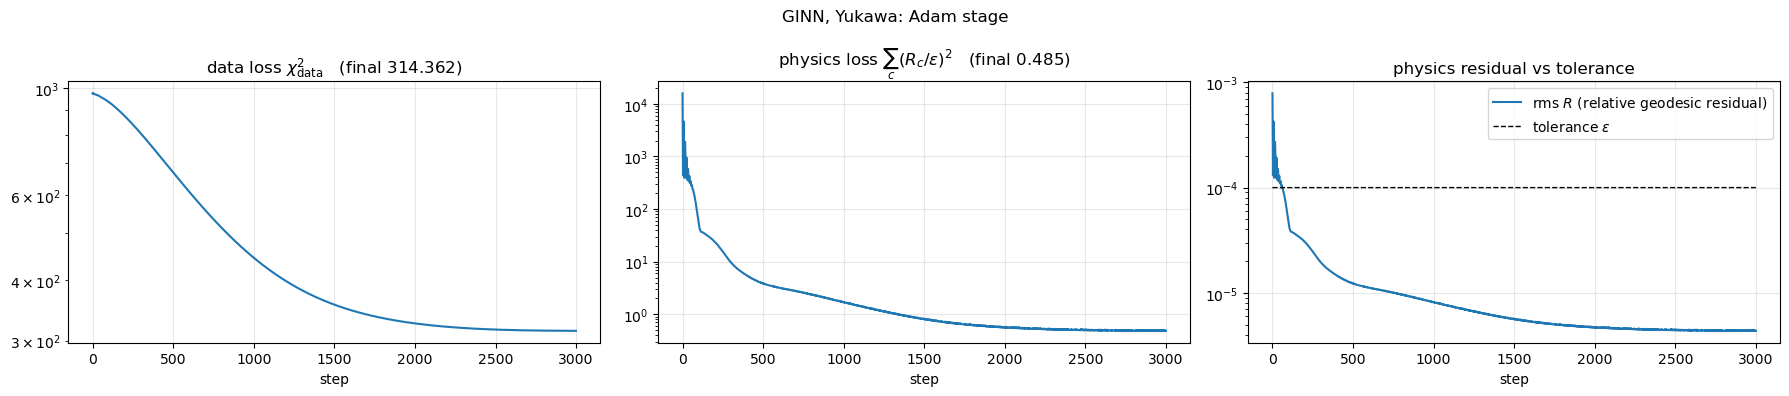

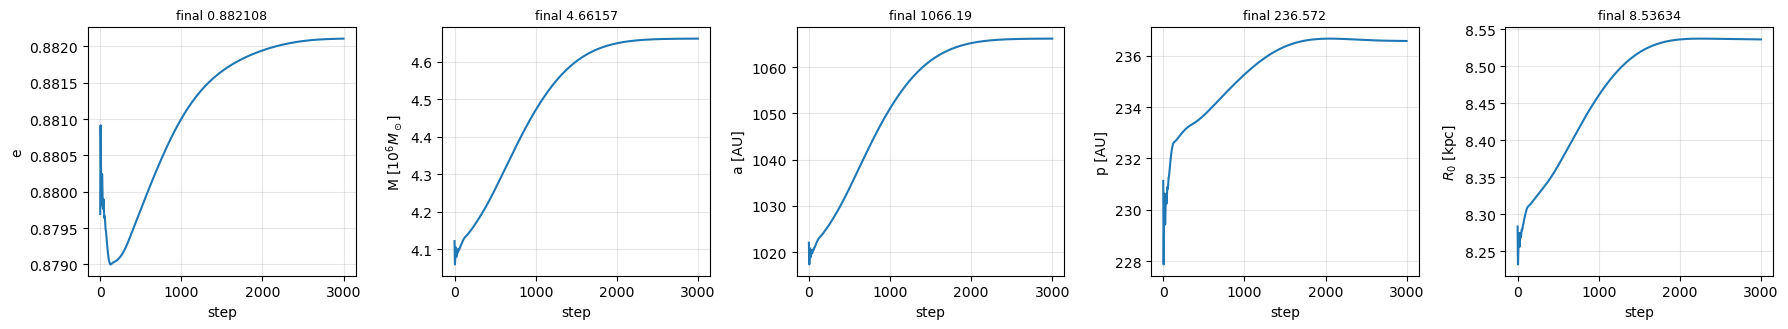

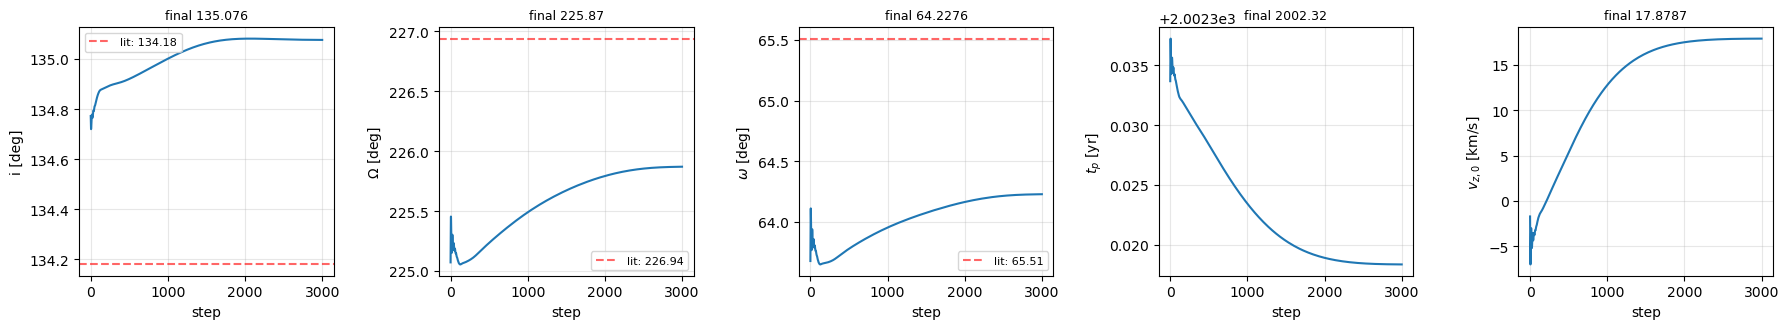

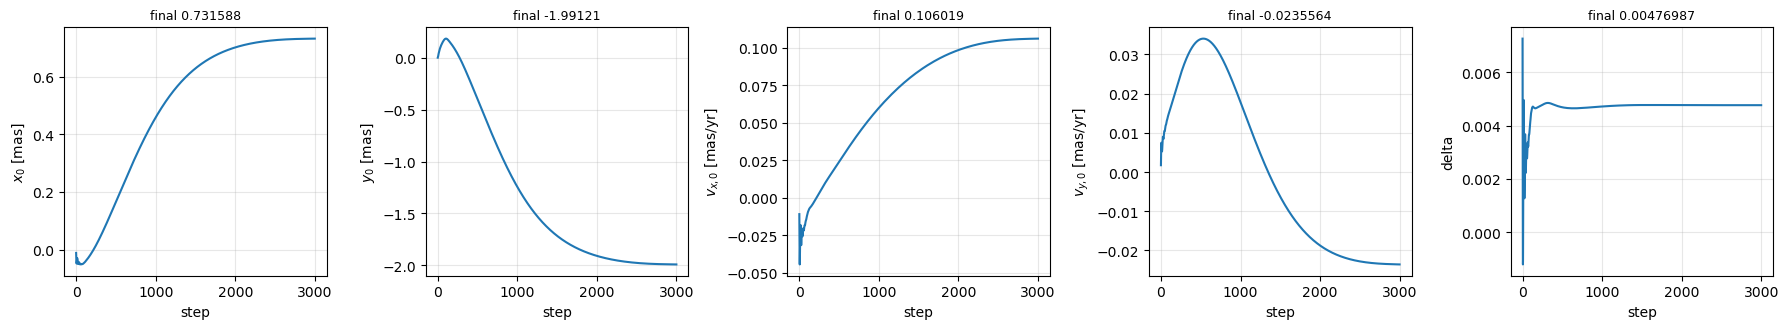

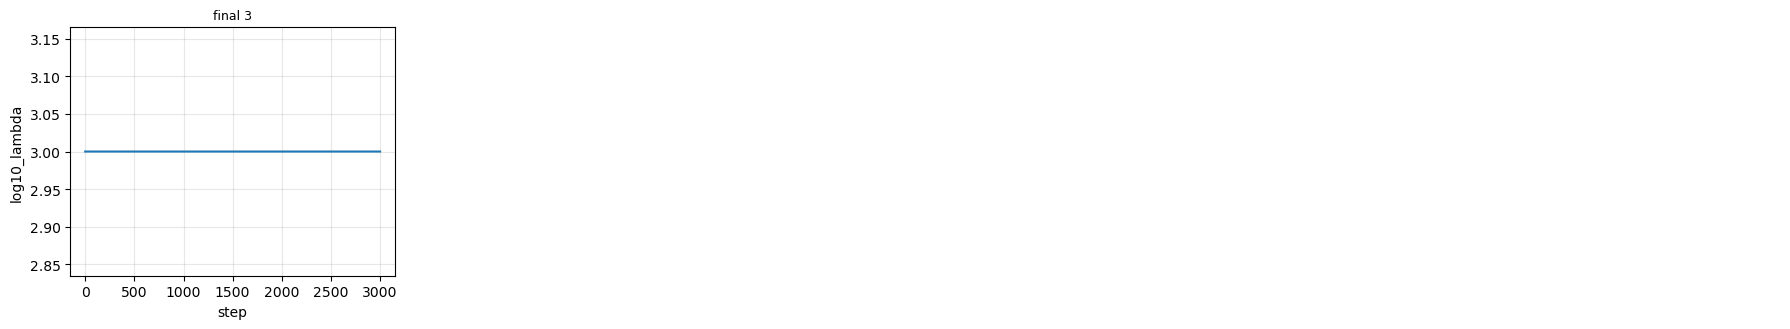

In [4]:
init = keplerian_prefit(data)
ginn, hist = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN,
                 hair_init=HAIR_INIT, fixed=tuple(set(HOLD) | set(FIXED)) if HOLD_HAIR_IN_ADAM else FIXED,
                 **MODEL, **TRAIN)
if HOLD_HAIR_IN_ADAM:
    for h in HOLD:
        ginn.fix(h, fixed=False)                 # release the hair for the polish
print('after Adam:', ginn.summary())
pl.plot_loss_history(hist, f'GINN, {metric.label}: Adam stage'); plt.show()
pl.plot_param_history(hist, lit=LIT); plt.show()

##  Gauss–Newton polish

C:\Users\phys6\Downloads\GINN_final\GINN\notebooks\..\ginn\analysis.py:99: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  chi2=float((r ** 2).sum()), marginalized=use_nn, timing=timing,


GN 0: predicted chi2 gain   25.710   delta = 0.0047699
GN 1: predicted chi2 gain    0.509   delta = 0.0074825
GN 2: predicted chi2 gain    4.288   delta = 0.014142
GN 3: predicted chi2 gain    2.160   delta = 0.018872
GN 4: predicted chi2 gain    0.809   delta = 0.019529
GN 5: predicted chi2 gain    0.492   delta = 0.019921
GN 6: predicted chi2 gain    0.266   delta = 0.020154
GN 7: predicted chi2 gain    0.138   delta = 0.020291
GN 8: predicted chi2 gain    0.069   delta = 0.020376
GN 9: predicted chi2 gain    0.032   delta = 0.020431
GN 10: predicted chi2 gain    0.015   delta = 0.020468

after polish: M = 4.2923e6 Msun | a = 1033.60 AU | e = 0.88541 | i = 134.169 | Om = 227.192 | om = 65.389 | t_p = 2002.3244 | D = 8.1191 kpc | vz0 = 13.05 km/s
   frame: x0 = +0.658 mas | y0 = -2.429 mas | vx0 = +0.2136 mas/yr | vy0 = +0.0474 mas/yr | delta = 0.02047 | log10_lambda = 3


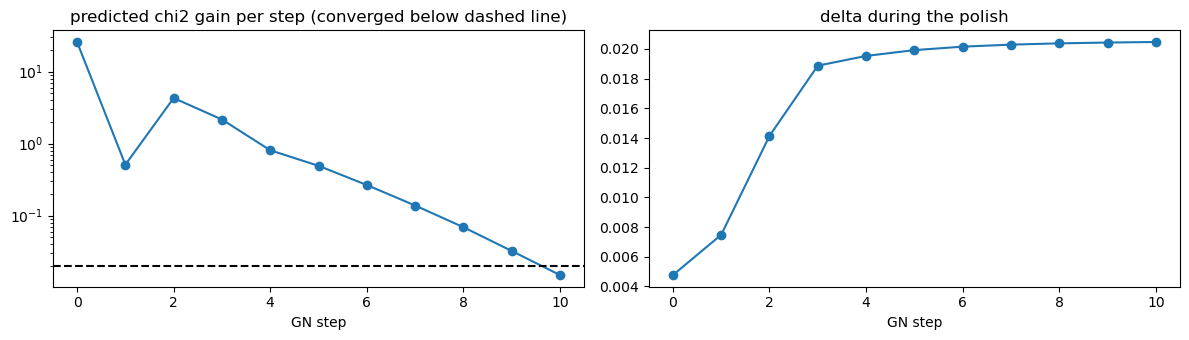

In [5]:
lap, gn_hist = an.gn_polish(ginn, data, cfg, **GN)
print('\nafter polish:', ginn.summary())
if HOLD:
    fig, ax = plt.subplots(1, 1 + len(HOLD), figsize=(6 * (1 + len(HOLD)), 3.5))
    ax[0].semilogy([max(h['chi2_gain'], 1e-4) for h in gn_hist], 'o-'); ax[0].axhline(GN['tol'], color='k', ls='--')
    ax[0].set_title('predicted chi2 gain per step (converged below dashed line)'); ax[0].set_xlabel('GN step')
    for a_, h in zip(ax[1:], HOLD):
        a_.plot([x[h] for x in gn_hist], 'o-'); a_.set_title(f'{h} during the polish'); a_.set_xlabel('GN step')
    plt.tight_layout(); plt.show()

## Results

In [6]:
post = an.posterior(ginn, data, cfg)
est = an.print_estimates(ginn, post)
S = an.sample_laplace(ginn, post, n=CORNER['n_samples'])
print()
for k in ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME:
    m_, lo_, hi_ = an.summarize(S)[k]; print(f"{k:6s} = {m_:.6g} +- {0.5 * (lo_ + hi_):.3g}")

         delta = 0.020468 +- 0.014   (1.5 sigma from GR)
  log10_lambda = 3   (held fixed)
[sample_laplace] 100.0% of samples inside the hair prior (the rest are rejected = Laplace x prior).

M      = 4.29169 +- 0.242
D      = 8.11884 +- 0.228
a      = 127.313 +- 1.36
e      = 0.885416 +- 0.00304
inc    = 134.167 +- 0.546
Omega  = 227.192 +- 0.741
omega  = 65.3908 +- 0.806
t0     = 2002.32 +- 0.00708
x0     = 0.658188 +- 0.225
y0     = -2.42967 +- 0.664
vx0    = 0.213858 +- 0.0769
vy0    = 0.0476025 +- 0.0757
vz0    = 13.0227 +- 8.08


In [7]:
# save the best fit and its posterior (used by compare_orbits.ipynb and 00_validation_and_checks.ipynb)
import os
os.makedirs('results', exist_ok=True)
torch.save(dict(model=ginn, hair=est, post=post, cfg=cfg), f'results/{METRIC}.pt')
print(f'saved results/{METRIC}.pt')

saved results/yukawa.pt


## Bayesian evidence
Laplace estimate of the evidence, from the same curvature as the error bars, relative to Schwarzschild (run 01_schwarzschild first). $\ln B>0$ favours this spacetime; the Occam term depends on the width of the hair prior.

In [8]:
ev = an.evidence(ginn, data, cfg, post)
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['evidence'] = ev
torch.save(r_, f'results/{METRIC}.pt')
ref_file = 'results/schwarzschild.pt'
ref = torch.load(ref_file, weights_only=False) if os.path.exists(ref_file) else {}
if METRIC == 'schwarzschild':
    print(f"chi2 = {ev['chi2']:.3f},   ln det Sigma = {ev['logdet_rest']:.3f}   (reference for all Bayes factors)")
elif 'evidence' in ref:
    an.print_bayes(metric.label, an.bayes_factor(ev, ref['evidence']))
else:
    print('run 01_schwarzschild.ipynb first: it provides the reference evidence')

model               dchi2  ln Occam  dln vol    ln B   evidence
Yukawa              -2.13     -3.35     0.02   -2.26   weak for Schwarzschild


## Corner plots

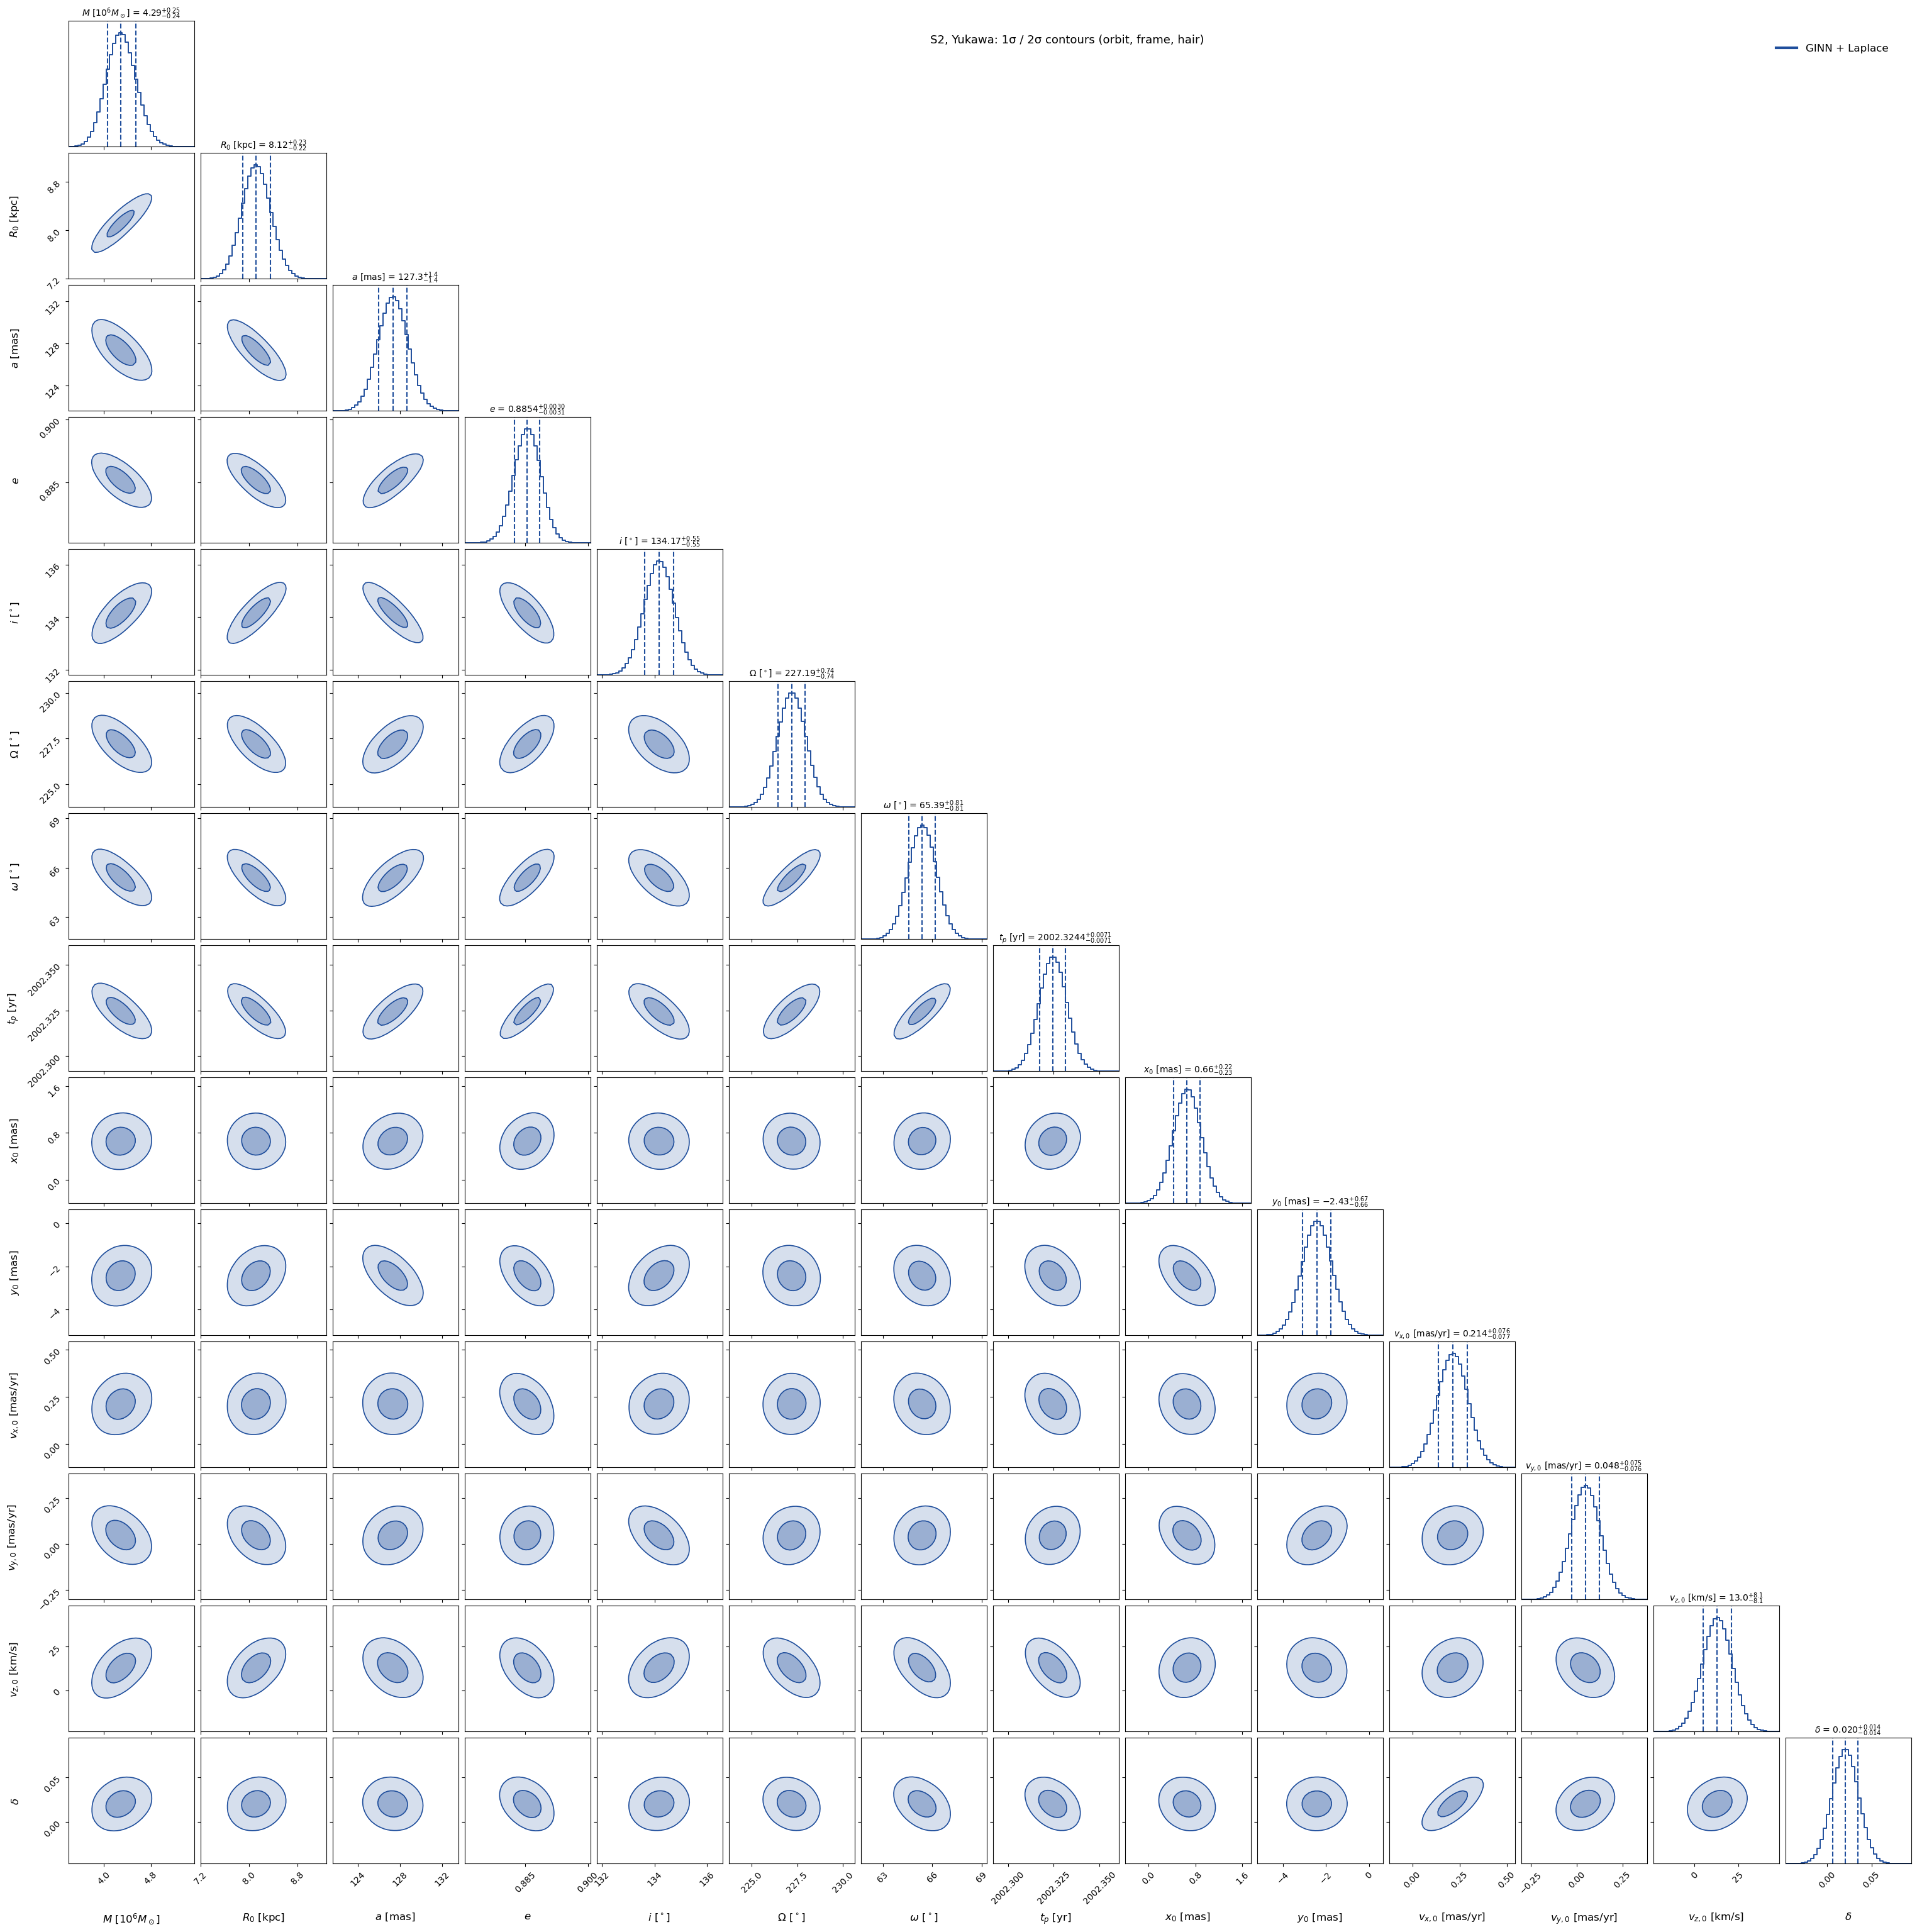

In [9]:
# one corner plot with ALL fitted parameters: orbit, hair and reference-frame offsets
keys = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME + list(HOLD)   # ALL parameters, one plot
pl.corner_plot([S], an.labels_for(ginn), keys, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: 1σ / 2σ contours (orbit, frame, hair)')
plt.savefig("corner_03_yukawa.png")
plt.show()

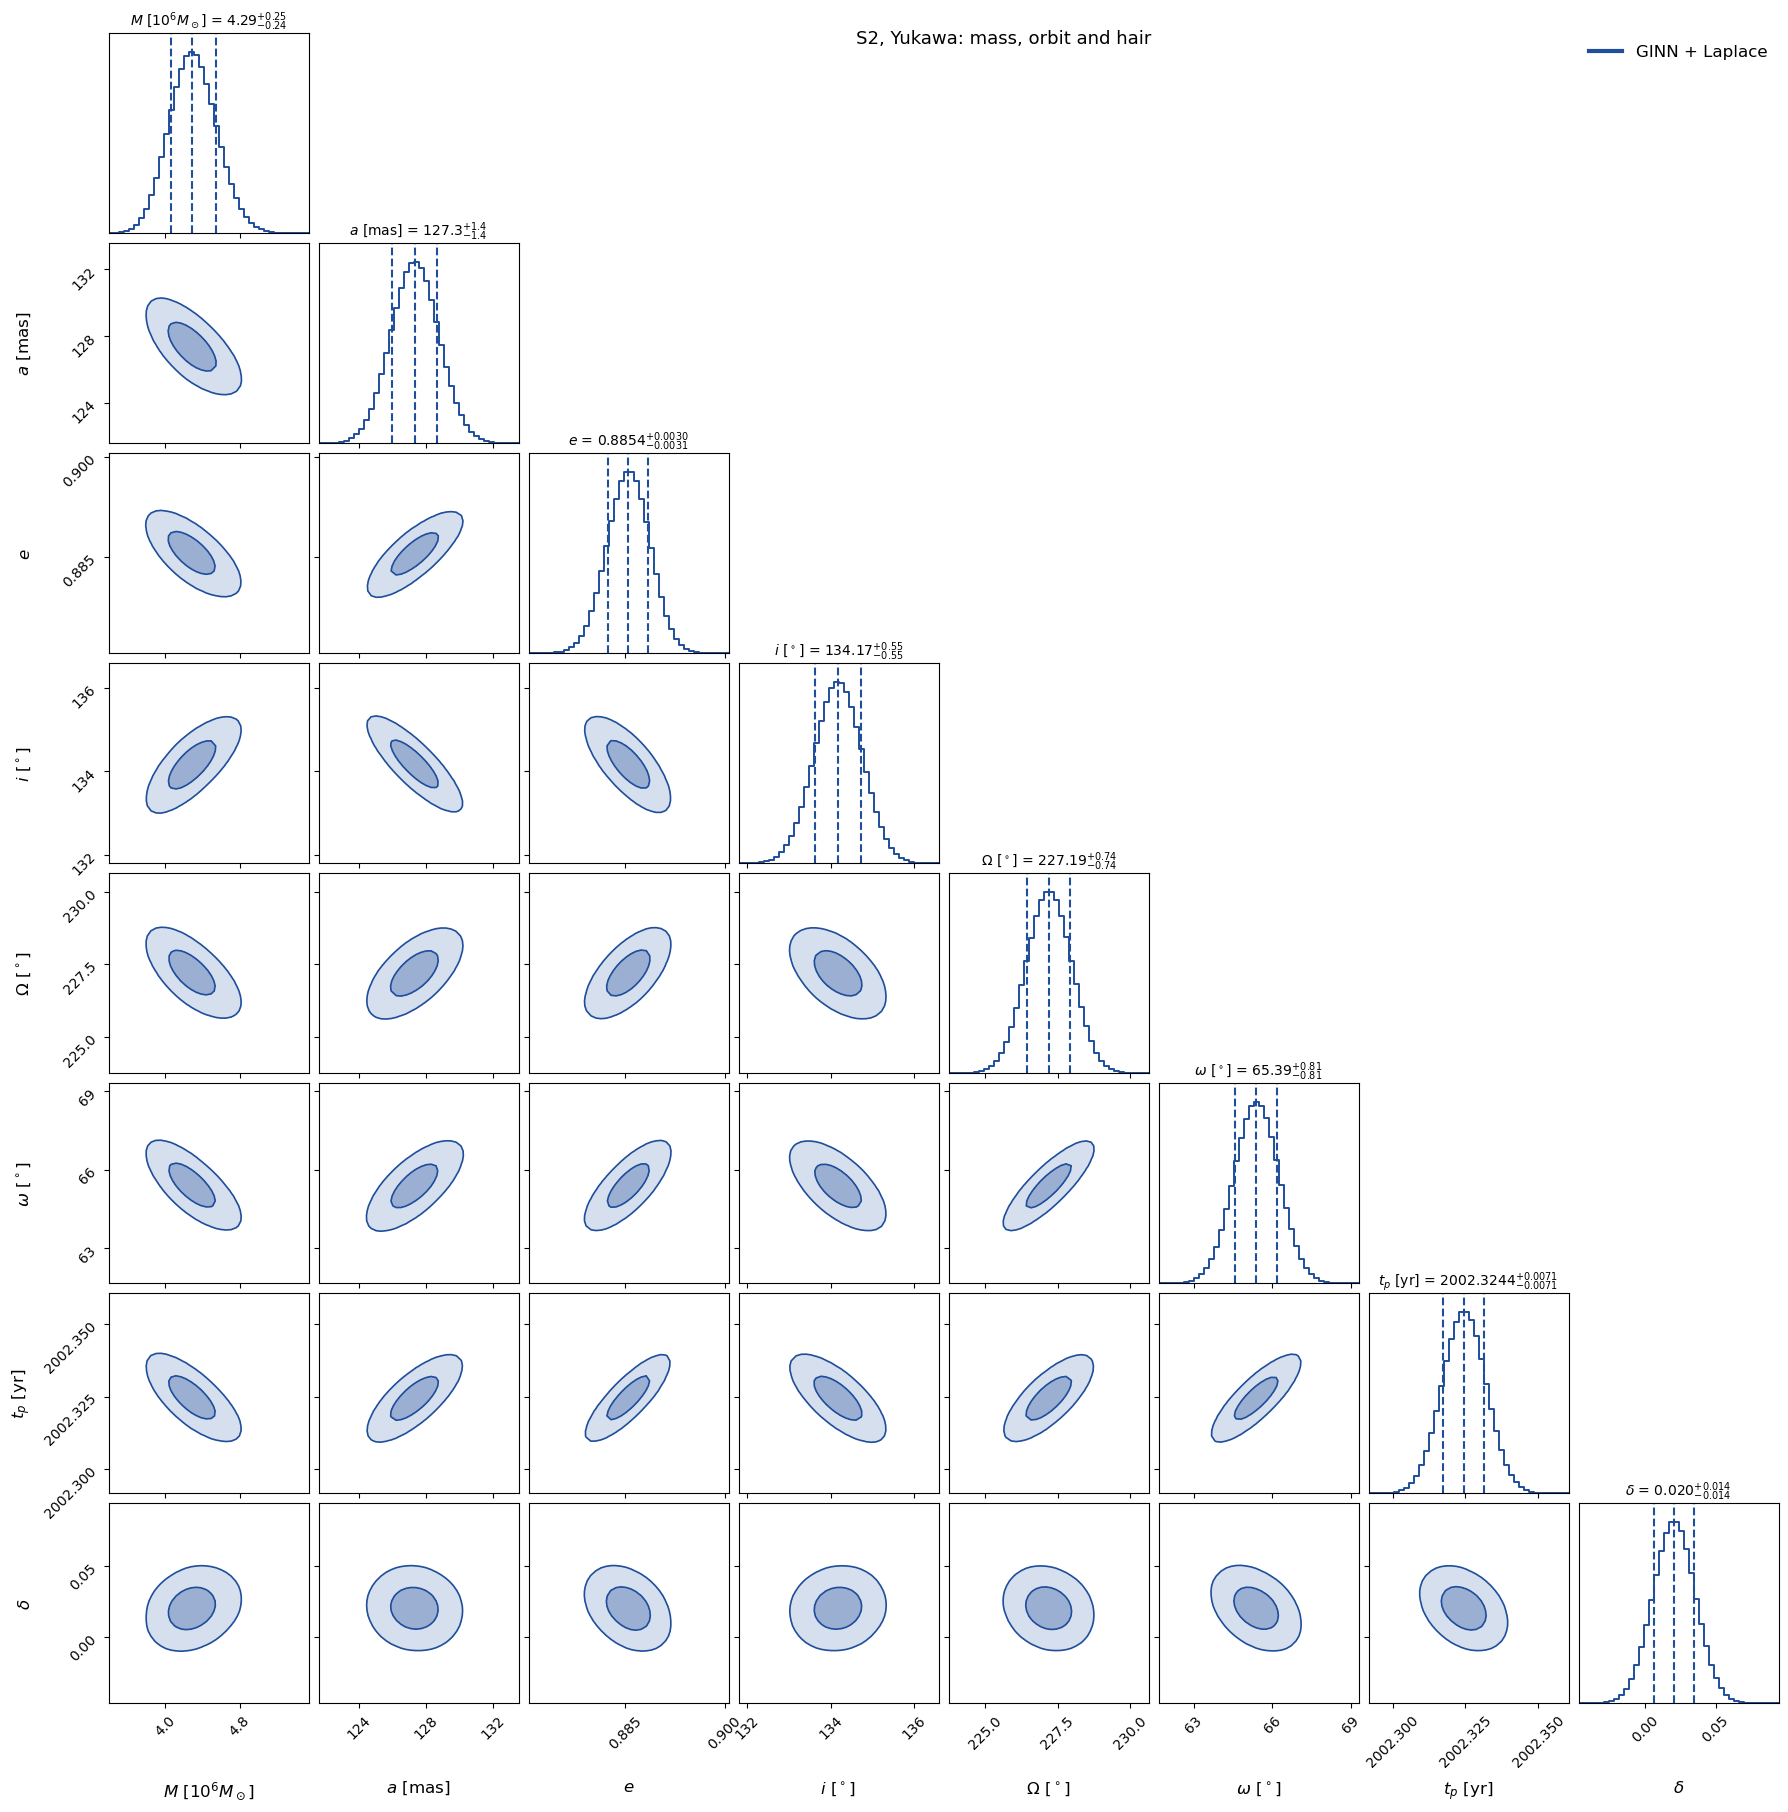

In [10]:
keys_red = ['M', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
pl.corner_plot([S], an.labels_for(ginn), keys_red, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: mass, orbit and hair')
plt.savefig("small_corner_03_yukawa.png")
plt.show()

In [11]:
#pl.plot_convergence(hist, S, gn_hist if HOLD else None, title=f'{metric.label}: convergence');plt.show()

In [12]:
# keep the posterior samples for the summary plots in 09_compare_orbits
import os
res_file = f'results/{METRIC}.pt'
if os.path.exists(res_file):
    r_ = torch.load(res_file, weights_only=False)
    r_['samples'] = {k: np.asarray(v)[:20000] for k, v in S.items()}
    torch.save(r_, res_file)

## Beyond the quadratic approximation
The data residuals are expanded to second order in the physical parameters, with the network eliminated to the same order, so that $\chi^2$ contains terms up to fourth order. This posterior is sampled with MCMC and compared with the Gauss–Newton + Laplace result above: shifts of the mean in units of the Laplace $\sigma$, ratio of the widths, and skewness. The comparison with the exact geodesic solver is in 00_validation_and_checks.

The chain is shorter than 50 times the integrated autocorrelation time for 4 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 194;
tau: [218.04501861 173.41202478 185.73067605 179.10633687 184.99654097
 154.35702823 181.96997981 180.59804788 177.62623433 171.78186637
 198.39608858 164.14056948 201.76834487 212.99172581]


higher-order MCMC: 2495 effective samples

             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew
M               4.29909 +- 0.242     |      +0.10       0.969       +0.19 |
D               8.12213 +- 0.228     |      +0.07       0.953       +0.06 |
a               127.315 +- 1.36      |      -0.01       0.946       +0.17 |
e              0.885379 +- 0.00303   |      -0.03       0.946       +0.02 |
inc             134.168 +- 0.545     |      +0.05       0.939       -0.03 |
Omega           227.194 +- 0.738     |      -0.07       0.974       -0.02 |
omega           65.3911 +- 0.806     |      -0.09       0.961       -0.05 |
t0              2002.32 +- 0.00709   |      -0.10       0.961       -0.16 |
delta          0.020445 +- 0.014     |      +0.08       1.005       -0.02 |

delta: 95% interval  Gauss-Newton + Laplace [-0.007042, +0.04789]   dali [-0.006048, +0.0489]


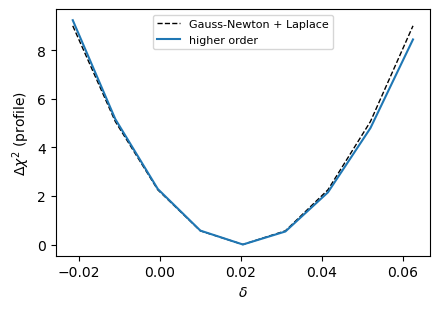

In [13]:
from ginn import higher_order as ho
HO_KEYS = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
P = ho.Expansion(ginn, data, post, cfg).expand()
chain = ho.sample(P, 'dali', n=600_000)
st = {'laplace': ho.stats(ho.sample(P, 'laplace'), HO_KEYS), 'dali': ho.stats(chain, HO_KEYS)}
print(f"higher-order MCMC: {chain['n_eff']:.0f} effective samples\n")
ho.print_compare(st, HO_KEYS, names=('dali',), hair=list(HOLD))
names = list(HOLD) or ['logM']
fig, axs = plt.subplots(1, len(names), figsize=(4.5 * len(names), 3.2), squeeze=False)
for a_, nm in zip(axs[0], names):
    pr = ho.profile(P, nm)
    if nm == 'logM':
        ho.plot_profile(a_, pr, label=r'$M\ [10^6 M_\odot]$', transform=lambda x: np.exp(x) / 1e6)
    else:
        ho.plot_profile(a_, pr, label=an.labels_for(ginn)[nm])
axs[0][0].legend(fontsize=8); plt.tight_layout(); plt.show()
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['higher_order'] = st
torch.save(r_, f'results/{METRIC}.pt')

## Some validation

chi2 (N_data = 334)                     RA      Dec      RV     total
  GINN                                         139.90   136.54   11.44   287.877
  without network                              140.21   140.35   11.56   292.112
  geodesic timing numerical                    139.89   136.53   11.44   287.858
we compare chi-squared improvement due to GINN and exact numerical correction - should be more or less equal


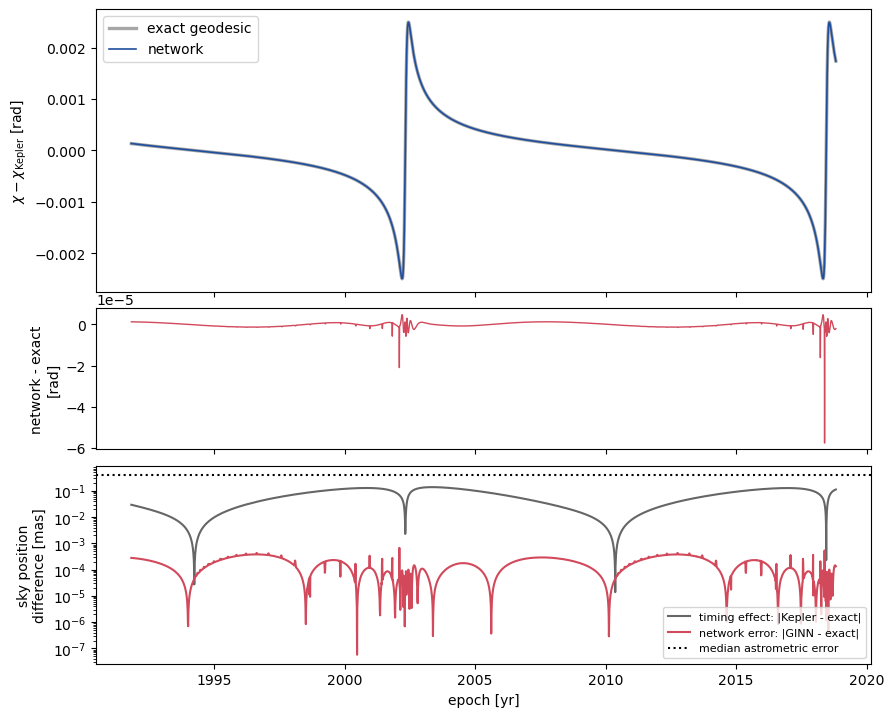

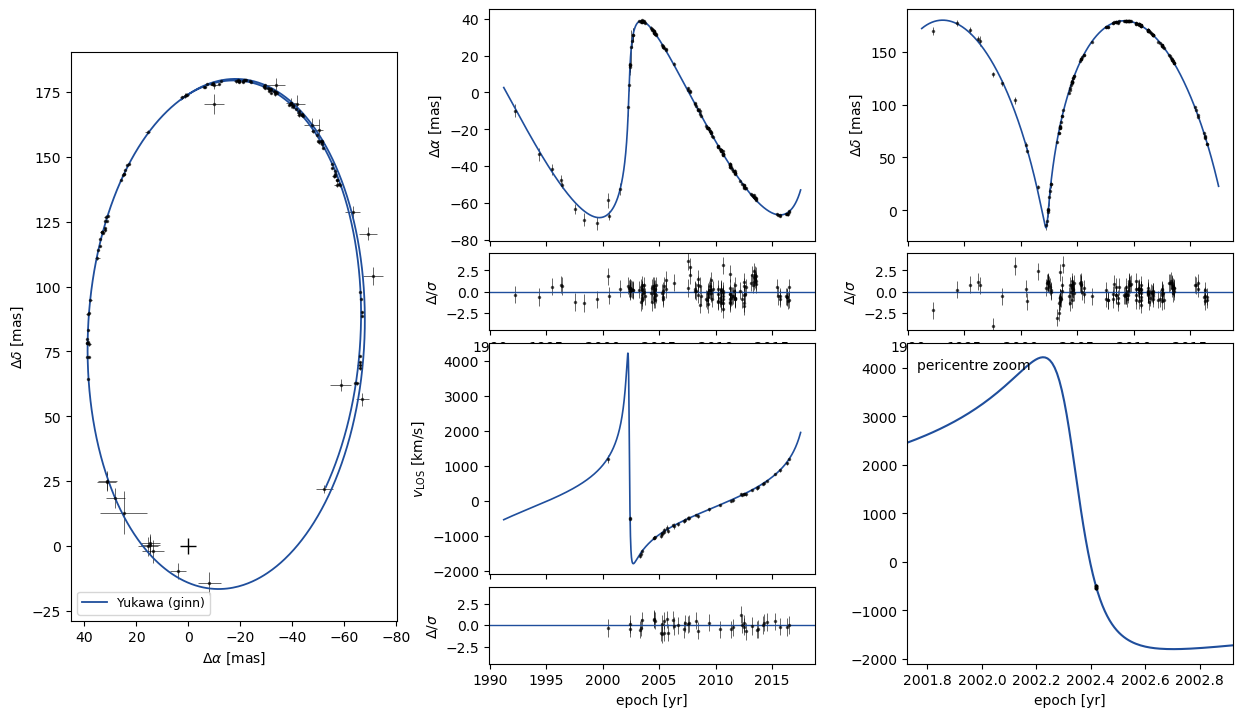

In [14]:
rep = an.nn_role_report(ginn, data, cfg, lap=post)
pl.plot_timing(rep['timing_curves'], data); plt.show()
pl.plot_fit(ginn, data); plt.show()

In [15]:
# exact, _ = fit(metric, data, init, timing='exact', cfg=cfg, n_steps=N_STEPS_EXACT,
#                hair_init=HAIR_INIT, fixed=FIXED, **TRAIN)
# lap_ex = an.laplace(exact, data, cfg)
# print('exact solver:', exact.summary())
# print('exact solver hair:', an.hair_estimates(exact, lap_ex))

## Multi-start 



start -0.05: delta: Adam +0.0048557 -> polish +0.020346 +- 0.014  | M = 4.2735, R0 = 8.1002 | chi2 Adam 1679.73 -> 287.86 (15 GN steps)
start +0.01: delta: Adam +0.0047699 -> polish +0.020468 +- 0.014  | M = 4.2922, R0 = 8.1192 | chi2 Adam 314.36 -> 287.88 (11 GN steps)
start +0.05: delta: Adam +0.0045684 -> polish +0.020061 +- 0.014  | M = 4.2786, R0 = 8.1050 | chi2 Adam 2055.38 -> 287.88 (14 GN steps)

         delta: spread across starts = 0.03 sigma  ->  CONSISTENT
             M: spread across starts = 0.08 sigma  ->  CONSISTENT
            R0: spread across starts = 0.08 sigma  ->  CONSISTENT


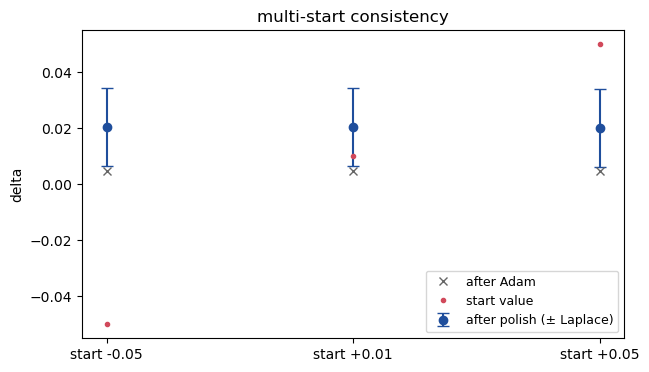

In [16]:
RUN_MULTISTART = True
MULTI_STARTS = [-0.05, 0.01, 0.05]
ms_rows = []
if RUN_MULTISTART:
    for s0 in MULTI_STARTS:
        if HOLD:
            hi, seed = {**HAIR_INIT, HOLD[0]: s0}, 0
        else:
            hi, seed = HAIR_INIT, int(s0)
        m_, h_ = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN, hair_init=hi,
                     fixed=FIXED, seed=seed, progress=False, **MODEL, **TRAIN)
        adam = {k: float(m_.physical()['par'][k]) for k in HOLD}
        chi2_adam = an.chi2_parts(m_, data)['total']
        lap_, gh_ = an.gn_polish(m_, data, cfg, verbose=False, **GN)
        post_ = an.posterior(m_, data, cfg, verbose=False)
        S_ = an.sample_laplace(m_, post_, n=20000, verbose=False)
        row = dict(start=s0, adam=adam, chi2_adam=chi2_adam, est=an.hair_estimates(m_, post_),
                   chi2=an.chi2_parts(m_, data)['total'], steps=len(gh_),
                   M=an.summarize(S_)['M'], D=an.summarize(S_)['D'])
        ms_rows.append(row)
        txt = '  '.join(f"{k}: Adam {row['adam'][k]:+.5g} -> polish {row['est'][k][0]:+.5g} +- {row['est'][k][1]:.3g}" for k in HOLD)
        print(f"start {s0:+g}: {txt}  | M = {row['M'][0]:.4f}, R0 = {row['D'][0]:.4f} | chi2 Adam {chi2_adam:.2f} -> {row['chi2']:.2f} ({row['steps']} GN steps)")
    def spread(vals, sig):
        return (max(vals) - min(vals)) / sig
    sym = lambda k, v: abs(v) if k in an.SQUARED_HAIR else v
    checks = [(k, [sym(k, r['est'][k][0]) for r in ms_rows], np.mean([r['est'][k][1] for r in ms_rows])) for k in HOLD]
    checks += [('M', [r['M'][0] for r in ms_rows], np.mean([0.5 * (r['M'][1] + r['M'][2]) for r in ms_rows])),
               ('R0', [r['D'][0] for r in ms_rows], np.mean([0.5 * (r['D'][1] + r['D'][2]) for r in ms_rows]))]
    print()
    for k, vals, sig in checks:
        sp = spread(vals, sig)
        print(f"{k:>14s}: spread across starts = {sp:.2f} sigma  ->  " +
              ('CONSISTENT' if sp < 0.2 else 'NOT CONSISTENT (increase N_STEPS_GINN or GN n_iter)'))
    if HOLD:
        k = HOLD[0]
        fig, ax = plt.subplots(figsize=(7, 4))
        xs = np.arange(len(ms_rows))
        ax.errorbar(xs, [r['est'][k][0] for r in ms_rows], [r['est'][k][1] for r in ms_rows], fmt='o',
                    color='#1f4e9c', capsize=4, label='after polish (± Laplace)')
        ax.plot(xs, [r['adam'][k] for r in ms_rows], 'x', color='0.4', label='after Adam')
        ax.plot(xs, [r['start'] for r in ms_rows], '.', color='#d1495b', label='start value')
        ax.set_xticks(xs); ax.set_xticklabels([f"start {r['start']:+g}" for r in ms_rows])
        ax.set_ylabel(k); ax.legend(fontsize=9); ax.set_title('multi-start consistency'); plt.show()

## Repeat for other values of $\lambda$
Each value starts from the model above. Orbit, hair and network are re-fitted with Adam (hair free), then polished; Laplace gives the errors.

log10_lambda = 3.5: delta = 0.1378 +- 0.0903  (9 GN steps)
log10_lambda = 4.0: delta = 0.5 +- 1.25  (4 GN steps)


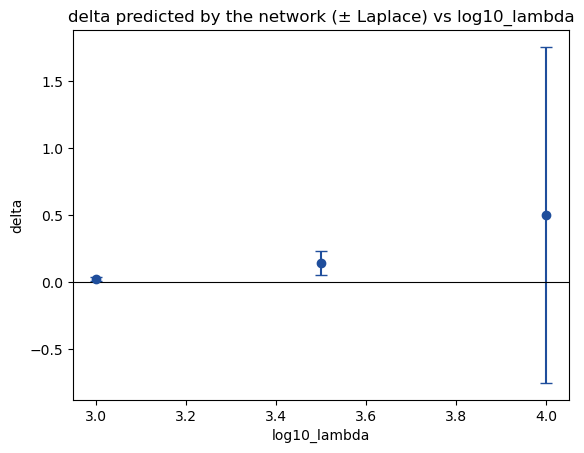

In [17]:
rows = [(float(ginn.physical()['par'][SCAN[0]]), *est[HOLD[0]])]
prev = ginn
for v in SCAN[1][1:]:
    m = copy.deepcopy(prev); m.set_value(SCAN[0], v)
    _ = train(m, data, cfg, n_steps=N_STEPS_WARM, progress=False, **TRAIN)   # hair free
    lap_v, gh = an.gn_polish(m, data, cfg, verbose=False, **GN)
    e_ = an.hair_estimates(m, lap_v)
    rows.append((v, *e_[HOLD[0]])); prev = m
    print(f"{SCAN[0]} = {v}: {HOLD[0]} = {e_[HOLD[0]][0]:.4g} +- {e_[HOLD[0]][1]:.3g}  ({len(gh)} GN steps)")
rows = np.array(rows)
plt.errorbar(rows[:, 0], rows[:, 1], rows[:, 2], fmt='o', color='#1f4e9c', capsize=4)
plt.axhline(0, color='k', lw=0.8); plt.xlabel(SCAN[0]); plt.ylabel(HOLD[0])
plt.title(f'{HOLD[0]} predicted by the network (± Laplace) vs {SCAN[0]}'); plt.show()

In [18]:
import copy
from scipy.stats import norm
from scipy.optimize import brentq
LAMBDA_AU = np.logspace(1.0, 4.5, 15)          # 10 AU to ~3e4 AU
GN_SCAN = dict(GN, n_iter=15)
PRIOR = (-0.5, 0.5)
 
def abs_upper_limit(mu, s, lo=PRIOR[0], hi=PRIOR[1], p=0.95):
    Z = norm.cdf((hi - mu) / s) - norm.cdf((lo - mu) / s)
    F = lambda b: (norm.cdf((min(b, hi) - mu) / s) - norm.cdf((max(-b, lo) - mu) / s)) / Z - p
    return brentq(F, 1e-9, hi) if F(hi) > 0 else hi
 
def scan_from(model, lams):
    out, m = [], copy.deepcopy(model)
    for lam in lams:
        m.fix('log10_lambda', fixed=False); m.set_value('log10_lambda', float(np.log10(lam))); m.fix('log10_lambda')
        lap_l, gh_l = an.gn_polish(m, data, cfg, verbose=False, **GN_SCAN)
        d, s = an.hair_estimates(m, lap_l)['delta']
        phys = an.physics_residual_stats(m)['rms']
        out.append(dict(lam=lam, delta=d, sigma=s, bound=abs_upper_limit(d, s),
                        chi2=an.chi2_parts(m, data)['total'], phys=phys, steps=len(gh_l)))
        print(f"lambda = {lam:9.1f} AU:  delta = {d:+.4f} +- {s:.4f}   |delta| < {out[-1]['bound']:.4f} (95%)   "
              f"chi2 = {out[-1]['chi2']:.2f}   physics rms = {phys:.1e}   ({len(gh_l)} GN steps)")
    return out
 
# walk down and up from the lambda of the main fit, so each fit starts close to the previous one
lam0 = 10 ** float(ginn.physical()['par']['log10_lambda'])
down = scan_from(ginn, sorted([l for l in LAMBDA_AU if l <= lam0], reverse=True))
up = scan_from(ginn, sorted([l for l in LAMBDA_AU if l > lam0]))
scan = sorted(down + up, key=lambda r: r['lam'])
 
lam = np.array([r['lam'] for r in scan]); bnd = np.array([r['bound'] for r in scan])
k = int(np.argmin(bnd))
print(f"\ntightest limit: |delta| < {bnd[k]:.4f} (95%) at lambda = {lam[k]:.0f} AU = {lam[k] * 1.495978707e11:.2e} m")
if np.any([r['phys'] > 1e-4 for r in scan]):
    print("WARNING: at some lambda the network does not satisfy the equation of motion (physics rms > 1e-4); "
          "check those points with the exact solver or a larger nn_out_scale")
np.savez('results/yukawa_scan.npz', **{key: np.array([r[key] for r in scan]) for key in scan[0]})
 

lambda =    1000.0 AU:  delta = +0.0205 +- 0.0140   |delta| < 0.0435 (95%)   chi2 = 287.88   physics rms = 1.1e-05   (1 GN steps)
lambda =     562.3 AU:  delta = +0.0101 +- 0.0080   |delta| < 0.0232 (95%)   chi2 = 288.39   physics rms = 1.3e-05   (6 GN steps)
lambda =     316.2 AU:  delta = +0.0067 +- 0.0057   |delta| < 0.0161 (95%)   chi2 = 288.70   physics rms = 1.3e-05   (4 GN steps)
lambda =     177.8 AU:  delta = +0.0059 +- 0.0052   |delta| < 0.0145 (95%)   chi2 = 288.68   physics rms = 6.2e-06   (10 GN steps)
lambda =     100.0 AU:  delta = +0.0078 +- 0.0064   |delta| < 0.0183 (95%)   chi2 = 288.53   physics rms = 6.5e-06   (4 GN steps)
lambda =      56.2 AU:  delta = +0.0144 +- 0.0120   |delta| < 0.0341 (95%)   chi2 = 288.47   physics rms = 7.1e-06   (4 GN steps)
lambda =      31.6 AU:  delta = +0.0468 +- 0.0462   |delta| < 0.1228 (95%)   chi2 = 288.47   physics rms = 4.7e-06   (15 GN steps)
lambda =      17.8 AU:  delta = +0.0830 +- 0.5482   |delta| < 0.4678 (95%)   chi2 = 289.

tightest limit: |delta| < 0.0145 (95%) at lambda = 178 AU = 2.66e+13 m


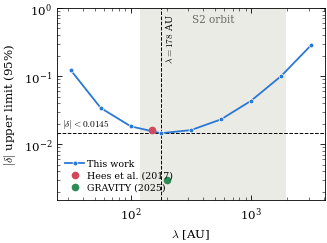

C:\Users\phys6\AppData\Local\Temp\ipykernel_29360\2786987069.py:54: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=6.8, loc='upper left', handletextpad=0.3)


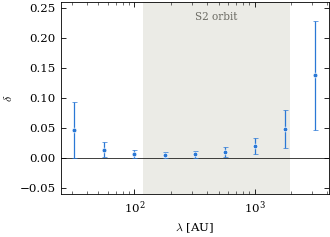

In [19]:
AU_M = 1.495978707e11

lam = np.array([r['lam'] for r in scan]); dl = np.array([r['delta'] for r in scan])
sg = np.array([r['sigma'] for r in scan])
ub = np.array([r['bound'] for r in scan])
ok = ub < 0.9 * PRIOR[1]                      # constrained points (limit well inside the prior)
k = int(np.argmin(ub))
P_ = ginn.physical(); r_p = float(P_['a']) * (1 - float(P_['e'])); r_a = float(P_['a']) * (1 + float(P_['e']))
print(f"tightest limit: |delta| < {ub[k]:.4f} (95%) at lambda = {lam[k]:.0f} AU = {lam[k] * AU_M:.2e} m")

plt.rcParams.update({'font.family': 'serif', 'mathtext.fontset': 'cm', 'font.size': 8.5,
                     'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
                     'xtick.minor.width': 0.4, 'ytick.minor.width': 0.4, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
                     'legend.frameon': False, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02})
BLUE, RED, GREEN, INK, MUTED, BAND = '#2a78d6', '#d1495b', '#2e8b57', '#1f1f1e', '#6b6a63', '#ebebe6'
W = 3.46                                       # A&A single column [inch]

def frame(ax):
    ax.set_xscale('log'); ax.set_xlim(lam[ok].min() / 1.3, lam[ok].max() * 1.3)
    ax.axvspan(r_p, r_a, color=BAND, lw=0, zorder=0)
    ax.set_xlabel(r'$\lambda$ [AU]')

# ---------- Figure 1: upper limit on |delta|
fig, ax = plt.subplots(figsize=(W, 2.5))
frame(ax)
ax.plot(lam[ok], ub[ok], '-o', color=BLUE, lw=1.3, ms=3.4, mec='white', mew=0.5, zorder=3, label='This work')
ax.plot(150, 0.016, 'o', color=RED, ms=4.5, zorder=5, label='Hees et al. (2017)')
ax.plot(3e13 / AU_M, 0.003, 'o', color=GREEN, ms=4.5, zorder=5, label='GRAVITY (2025)')

lam_k, ub_k = lam[k], ub[k]
ax.axvline(lam_k, color='k', ls='--', lw=0.7, zorder=2)
ax.axhline(ub_k, color='k', ls='--', lw=0.7, zorder=2)
ax.text(lam_k * 1.07, 0.97, rf'$\lambda = {lam_k:.0f}$ AU', rotation=90, ha='left', va='top',
        fontsize=6.8, color='k', transform=ax.get_xaxis_transform())
ax.text(0.02, ub_k * 1.1, rf'$|\delta| < {ub_k:.4f}$', ha='left', va='bottom',
        fontsize=6.8, color='k', transform=ax.get_yaxis_transform())

ax.set_yscale('log'); ax.set_ylim(1.5e-3, 1.0)
ax.set_ylabel(r'$|\delta|$ upper limit (95%)')
ax.text(np.sqrt(r_p * r_a), 0.8, 'S2 orbit', ha='center', va='top', fontsize=7.5, color=MUTED)
ax.legend(fontsize=6.8, loc='lower left', handletextpad=0.3, labelspacing=0.3)
fig.savefig('results/yukawa_delta_limit.pdf'); plt.show()

# ---------- Figure 2: best-fit delta and its 1-sigma error
fig, ax = plt.subplots(figsize=(W, 2.5))
frame(ax)
ax.axhline(0, color=INK, lw=0.6, zorder=1)
ax.errorbar(lam[ok], dl[ok], sg[ok], fmt='o', color=BLUE, ms=3.4, mec='white', mew=0.5, elinewidth=0.9,
            capsize=1.8, capthick=0.8, zorder=3)#, label=r'This work, best fit $\pm1\sigma$')
ax.set_ylim(-0.06, 0.26)
ax.set_ylabel(r'$\delta$')
ax.text(np.sqrt(r_p * r_a), 0.235, 'S2 orbit', ha='center', va='center', fontsize=7.5, color=MUTED)
ax.legend(fontsize=6.8, loc='upper left', handletextpad=0.3)
fig.savefig('results/yukawa_delta_bestfit.pdf'); plt.show()

In [20]:
d_min, s_min, b_min, l_min = dl[k], sg[k], ub[k], lam[k]
print(f"minimum: lambda = {l_min:.0f} AU = {l_min * AU_M:.2e} m,  delta = {d_min:.4f} +- {s_min:.4f},  "
      f"|delta| < {b_min:.4f} (95%)")

minimum: lambda = 178 AU = 2.66e+13 m,  delta = 0.0059 +- 0.0052,  |delta| < 0.0145 (95%)


tightest limit: |delta| < 0.0145 (95%) at lambda = 178 AU = 2.66e+13 m


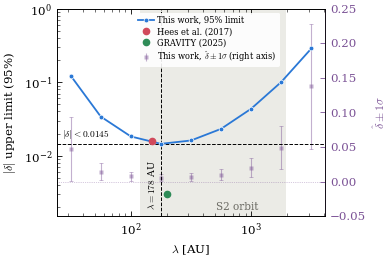

In [26]:
AU_M = 1.495978707e11

lam = np.array([r['lam'] for r in scan]); dl = np.array([r['delta'] for r in scan])
sg = np.array([r['sigma'] for r in scan])
ub = np.array([r['bound'] for r in scan])
ok = ub < 0.9 * PRIOR[1]                      # constrained points (limit well inside the prior)
k = int(np.argmin(ub))
P_ = ginn.physical(); r_p = float(P_['a']) * (1 - float(P_['e'])); r_a = float(P_['a']) * (1 + float(P_['e']))
print(f"tightest limit: |delta| < {ub[k]:.4f} (95%) at lambda = {lam[k]:.0f} AU = {lam[k] * AU_M:.2e} m")

plt.rcParams.update({'font.family': 'serif', 'mathtext.fontset': 'cm', 'font.size': 8.5,
                     'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
                     'xtick.minor.width': 0.4, 'ytick.minor.width': 0.4, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': False,
                     'legend.frameon': False, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02})
BLUE, RED, GREEN, INK, MUTED, BAND = '#2a78d6', '#d1495b', '#2e8b57', '#1f1f1e', '#6b6a63', '#ebebe6'
FIT = '#7a5195'                                # best fit +- 1 sigma (right axis)
W = 3.46                                       # A&A single column [inch]

fig, ax = plt.subplots(figsize=(W, 2.7))
ax.set_xscale('log'); ax.set_xlim(lam[ok].min() / 1.3, lam[ok].max() * 1.3)
ax.set_xlabel(r'$\lambda$ [AU]')

# right axis (linear): best-fit delta and its 1-sigma error, drawn faint behind the limit
ax2 = ax.twinx()
ax2.axvspan(r_p, r_a, color=BAND, lw=0, zorder=0)                    # S2 band at the very back
ax2.axhline(0, color=FIT, lw=0.5, ls=':', alpha=0.6, zorder=1)
ax2.errorbar(lam[ok], dl[ok], sg[ok], fmt='s', color=FIT, alpha=0.45, ms=2.6, mec='none', elinewidth=0.8,
             capsize=1.5, capthick=0.6, zorder=1)
ax2.set_ylim(-0.05, 0.25)
ax2.set_ylabel(r'$\hat\delta\pm1\sigma$', color=FIT)
ax2.tick_params(axis='y', which='both', direction='in', colors=FIT, width=0.6)
ax2.spines['right'].set_color(FIT)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)   # limit curve on top

# left axis (log): 95% upper limit on |delta|
ax.plot(lam[ok], ub[ok], '-o', color=BLUE, lw=1.3, ms=3.4, mec='white', mew=0.5, zorder=3, label='This work, 95% limit')
ax.plot(150, 0.016, 'o', color=RED, ms=4.5, zorder=5, label='Hees et al. (2017)')
ax.plot(3e13 / AU_M, 0.003, 'o', color=GREEN, ms=4.5, zorder=5, label='GRAVITY (2025)')
ax.errorbar([], [], [], fmt='s', color=FIT, alpha=0.45, ms=2.6, mec='none', elinewidth=0.8,
            label=r'This work, $\hat\delta\pm1\sigma$ (right axis)')     # legend entry only

lam_k, ub_k = lam[k], ub[k]
ax.axvline(lam_k, color='k', ls='--', lw=0.7, zorder=2)
ax.axhline(ub_k, color='k', ls='--', lw=0.7, zorder=2)
ax.text(lam_k / 1.07, 0.03, rf'$\lambda = {lam_k:.0f}$ AU', rotation=90, ha='right', va='bottom',
        fontsize=6.8, color='k', transform=ax.get_xaxis_transform())
ax.text(0.02, ub_k * 1.1, rf'$|\delta| < {ub_k:.4f}$', ha='left', va='bottom',
        fontsize=6.8, color='k', transform=ax.get_yaxis_transform())

ax.set_yscale('log'); ax.set_ylim(1.5e-3, 1.0)
ax.set_ylabel(r'$|\delta|$ upper limit (95%)')
ax.text(np.sqrt(r_p * r_a) * 1.6, 1.7e-3, 'S2 orbit', ha='center', va='bottom', fontsize=7.5, color=MUTED)
ax.legend(fontsize=6.0, loc='upper center', bbox_to_anchor=(0.56, 1.0), handletextpad=0.3, labelspacing=0.25,
          frameon=True, framealpha=0.9, edgecolor='none', facecolor='white')
fig.savefig('results/yukawa_delta_limit.pdf'); plt.show()